# Assignment 4 — One- and Two-Sample Tests

**Course:** STA1

**Group members:** Bibek Paudel, Dora Buruncuk, Supendra Bogati

## Table of contents
1. [Part 1 — One-sample decisions](#part1)
2. [Part 2 — Independent coating processes](#part2)
3. [Part 3 — Paired building-energy measurements](#part3)
4. [Part 4 — Comparing two independent proportions](#part4)
5. [Part 5 — AI-use and conclusion](#part5)

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t, ttest_1samp, shapiro, probplot, binom, binomtest
from statsmodels.stats.proportion import proportion_confint

DATA = "data/"

sensor = pd.read_csv(DATA + "assignment03_sensor_calibration.csv")   # Part 1
access = pd.read_csv(DATA + "assignment03_access_control.csv")       # Part 1

print(f"sensor: {sensor.shape[0]} rows x {sensor.shape[1]} columns")
print(f"access: {access.shape[0]} rows x {access.shape[1]} columns")

sensor: 64 rows x 2 columns
access: 240 rows x 2 columns


<a id="part1"></a>
# Part 1 — One-sample decisions

## Mean sensor error

> Use assignment03_sensor_calibration.csv. The engineering team asks whether population mean
> calibration error differs from zero; errors with absolute mean below $0.50\ ^\circ\mathrm C$ are
> regarded as small in practice.

**Population:** all temperature sensors of this type.

**Parameter:** $\mu$, the population mean calibration error in °C, where error = sensor reading −
reference temperature.

**Observational unit:** one sensor.

**Design:** one sample of 64 independently selected sensors. $\mu$ is compared with the fixed value
0 °C, so the effect is $\bar x - 0$.

**Assumptions:** independent errors from one population, and errors close to normal (or $n$ large
enough for $\bar X$ to be close to normal).

n = 64, mean = 0.1883 °C, s = 0.6257 °C, SE = 0.0782 °C


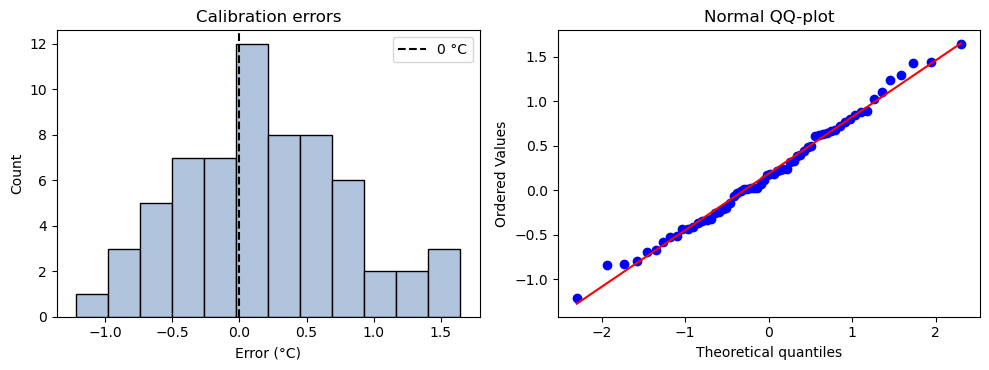

Shapiro–Wilk W = 0.990, p = 0.874


In [2]:
errors = sensor["calibration_error_c"].to_numpy()

n = errors.size
xbar = errors.mean()
s = errors.std(ddof=1)
se = s / np.sqrt(n)
print(f"n = {n}, mean = {xbar:.4f} °C, s = {s:.4f} °C, SE = {se:.4f} °C")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].hist(errors, bins=12, color="lightsteelblue", edgecolor="black")
axes[0].axvline(0, color="black", ls="--", label="0 °C")
axes[0].set(title="Calibration errors", xlabel="Error (°C)", ylabel="Count")
axes[0].legend()
probplot(errors, dist="norm", plot=axes[1])
axes[1].set_title("Normal QQ-plot")
fig.tight_layout()
plt.show()

W, p_sw = shapiro(errors)
print(f"Shapiro–Wilk W = {W:.3f}, p = {p_sw:.3f}")

**Assumption check:** the histogram is roughly symmetric, the QQ points follow the line, and
Shapiro–Wilk ($p = 0.874$) gives no evidence against normality, so the $t$ procedure is reasonable.
These checks cannot show independence; that depends on how the sensors were selected.

### a)

> State $H_0$, the two-sided $H_1$, and $\alpha=0.05$. Use a one-sample $t$ procedure and report the
> sample mean, test statistic, degrees of freedom, and two-sided $p$-value.

$$H_0: \mu = 0\ ^\circ\mathrm C \qquad H_1: \mu \ne 0\ ^\circ\mathrm C \qquad \alpha = 0.05$$

$$t = \frac{\bar x - 0}{s/\sqrt n}, \qquad \text{df} = n - 1$$

In [3]:
mu0 = 0.0
alpha = 0.05

t_obs = (xbar - mu0) / se
df = n - 1
p_two = 2 * t.sf(abs(t_obs), df)
res = ttest_1samp(errors, popmean=mu0, alternative="two-sided")   # check with SciPy

print(f"sample mean = {xbar:.4f} °C")
print(f"t = ({xbar:.5f} - 0) / {se:.5f} = {t_obs:.4f}")
print(f"df = {df}")
print(f"two-sided p = {p_two:.4f}")
print(f"SciPy check: t = {res.statistic:.4f}, df = {res.df}, p = {res.pvalue:.4f}")
print(f"decision at alpha = {alpha}:", "reject H0" if p_two < alpha else "fail to reject H0")

sample mean = 0.1883 °C
t = (0.18827 - 0) / 0.07822 = 2.4069
df = 63
two-sided p = 0.0190
SciPy check: t = 2.4069, df = 63, p = 0.0190
decision at alpha = 0.05: reject H0


### b)

> Interpret the $p$-value as a tail probability conditional on $H_0$ and the assumptions. State the
> decision and a contextual conclusion without treating the $p$-value as $P(H_0\mid\text{data})$.

**$p$-value:** if $\mu = 0$ and the assumptions hold, a $t$ statistic at least as far from 0 as
2.41, in either direction, would occur with probability 0.019. It is not the probability that $H_0$
is true.

**Decision:** $p = 0.019 < 0.05$, so we reject $H_0$.

**Conclusion:** the data give evidence that the population mean calibration error differs from
0 °C. The sample mean of 0.19 °C suggests the sensors read slightly high on average.

### c)

> Reuse or reconstruct the 95% $t$ interval and explain its duality with this two-sided test. Compare
> it with the practical limits and distinguish statistical significance from practical importance.

$$\bar x \pm t_{n-1,\,0.975}\,\frac{s}{\sqrt n}$$

In [4]:
ci_lo, ci_hi = t.interval(0.95, df, loc=xbar, scale=se)

print(f"95% t interval for mu = [{ci_lo:.4f}, {ci_hi:.4f}] °C")
print("0 °C inside the interval:", ci_lo <= 0 <= ci_hi)
print("interval inside the practical limits of ±0.50 °C:", -0.50 < ci_lo and ci_hi < 0.50)

95% t interval for mu = [0.0320, 0.3446] °C
0 °C inside the interval: False
interval inside the practical limits of ±0.50 °C: True


**Duality:** the interval and the two-sided test use the same $t$ distribution, SE and df. A value
$\mu_0$ is rejected at $\alpha = 0.05$ exactly when it lies outside the 95 % interval. 0 °C lies
outside $[0.0320,\ 0.3446]$ °C, which matches the rejection in a).

**Practical importance:** the whole interval lies inside $\pm 0.50$ °C, so even the largest
plausible mean error, 0.34 °C, is small in practice. The result is statistically significant but not
practically important: the sensors read slightly high on average, but by too little to matter.

**Limitation:** the result applies only to sensors like these 64. The errors are measured against
the reference temperature, so a bias in the reference would look like a sensor error.

## False-rejection probability

> Use assignment03_access_control.csv. The pre-specified question is whether the false-rejection
> probability exceeds the 5% target.

**Population:** all legitimate login attempts under the test conditions.

**Parameter:** $p$, the probability that a legitimate attempt is falsely rejected.

**Observational unit:** one login attempt.

**Design:** 240 independently staged attempts. If the attempts are independent with the same $p$,
the number of false rejections is $X \sim \text{Bin}(240, p)$. $p$ is compared with the fixed
target 0.05.

### a)

> State the one-sided hypotheses. Perform an exact binomial test and report $\hat p$, the $p$-value,
> decision, and conclusion.

$$H_0: p \le 0.05 \qquad H_1: p > 0.05 \qquad \alpha = 0.05$$

The exact $p$-value is the upper tail of the binomial distribution at the null value $p_0 = 0.05$:

$$p\text{-value} = P(X \ge x \mid p = 0.05)$$

In [5]:
y = access["false_reject"]

n = len(y)
x = int(y.sum())
p_hat = x / n
res_b = binomtest(x, n=n, p=0.05, alternative="greater")

print(f"n = {n}, x = {x}, p_hat = {p_hat:.4f}")
print(f"expected false rejections if p = 0.05: {n * 0.05:.0f}")
print(f"exact one-sided p = P(X >= {x} | p = 0.05) = {res_b.pvalue:.4f}")
print(f"check with binom.sf: {binom.sf(x - 1, n, 0.05):.4f}")   # sf(x - 1) = P(X >= x)
print(f"decision at alpha = {alpha}:", "reject H0" if res_b.pvalue < alpha else "fail to reject H0")

n = 240, x = 20, p_hat = 0.0833
expected false rejections if p = 0.05: 12
exact one-sided p = P(X >= 20 | p = 0.05) = 0.0185
check with binom.sf: 0.0185
decision at alpha = 0.05: reject H0


**Decision:** $p = 0.0185 < 0.05$, so we reject $H_0$.

**Conclusion:** that is 20 false rejections in 240 attempts ($\hat p = 0.0833$), more than the 12
expected at the 5 % target. The data give evidence that the false-rejection probability under the
test conditions exceeds 5 %.

**Limitation:** the attempts were staged under test conditions, so the false-rejection rate for real
users may differ.

### b)

> Use the Wilson interval as an estimate of plausible values, while explaining why a two-sided Wilson
> interval is not the exact dual of a one-sided exact test.

In [6]:
wilson_lo, wilson_hi = proportion_confint(x, n, alpha=0.05, method="wilson")
print(f"95% Wilson interval for p = [{wilson_lo:.4f}, {wilson_hi:.4f}]")

95% Wilson interval for p = [0.0546, 0.1252]


**Plausible values:** false-rejection probabilities from about 5.5 % to 12.5 % are compatible with
the data. The whole interval lies above the 5 % target.

**Why it is not the exact dual:** duality needs a two-sided test and an interval from the same
method at the same level. Here the test is one-sided at 5 % and uses the exact binomial
distribution, while the Wilson interval is two-sided (2.5 % in each tail) and uses the normal
approximation. Here both point the same way, but duality does not guarantee that, so the decision
comes from the exact test and the interval describes how large $p$ may be.

### c)

> Describe Type I and Type II errors in one of the two one-sample studies and state an operational
> consequence of each.

For the false-rejection study ($H_0: p \le 0.05$):

**Type I error (false positive):** concluding that $p$ exceeds 5 % when it does not. Its
probability is at most $\alpha = 0.05$. Consequence: the team spends time retuning, or delays the
release of, a system that already meets the target.

**Type II error (false negative):** failing to conclude that $p$ exceeds 5 % when it does. Its
probability is $\beta$, and the power is $1 - \beta$. Consequence: the system is released and more
legitimate users are locked out than the target allows, causing support calls and lost work.